# HW3: Unsupervised Learning - Clustering, TF-IDF & Dimensionality Reduction

In this assignment you will build intuition for unsupervised learning from the ground up and
then apply it to real text data. You will:

1. Implement the K-Means assignment & update steps from scratch in NumPy.
2. Compute TF-IDF by hand on a toy corpus to see what the formula rewards and penalizes.
3. Build a text clustering pipeline with `TfidfVectorizer` + `KMeans` on the 20 Newsgroups dataset.
4. Interpret clusters from their centroids' top terms.
5. Reduce the data to 2D with **PCA** and **UMAP** and explain why they look different.
6. Compare your clusters against the true categories and reason about which get confused and why.

Fill in every cell marked **`TODO`** and answer every **Markdown** question cell. Run the notebook
top-to-bottom before submitting so all outputs (tables, plots) are visible.

**Cell tags.** Every actionable cell is tagged so you know what it expects:
- `[WRITE CODE]` - a blank code cell for you to fill in.
- `[RUN ONLY]` - provided code; just run it (nothing to edit or answer).
- `[ANSWER]` - a question cell; type your response where it says *(Your answer here.)*.
- `[REQUIRED]` - a cell you must complete (your info, disclosures, and work-history link); omitting these carries grade penalties - see **Submission requirements**.

A `[WRITE CODE]` or `[RUN ONLY]` cell followed by an `[ANSWER]` cell means: do that cell, then answer the question about its output.

**[REQUIRED]**

## Student information & disclosures

| | |
|---|---|
| **Name** | Amit Murkalmath |
| **Student ID** | 122097179 |
| **Work format** | Individual |

**External source disclosure.** Cite every external source you used and what you got from each one,
including textbooks, websites, Stack Overflow answers, library documentation, YouTube videos, and
forum posts.

- Scikit-learn documentation (TfidfVectorizer, KMeans, TruncatedSVD, PCA, contingency_matrix): syntax and parameters.
- UMAP-learn documentation: metric='cosine', n_neighbors, and min_dist configurations.
- Course lecture slides on Unsupervised Learning and Text Clustering (DATA 602).

**AI usage disclosure.** Describe how you used AI tools (e.g., ChatGPT, Claude, Copilot), if at all,
and for which parts of the assignment. Any use of AI tools must comply with the course AI policy.

Used Google Gemini to discuss NumPy array broadcasting for vectorizing L2 distance in K-Means, verify TF-IDF inverse document frequency conventions, and assist with drafting interpretations for the clustering comparison. All code implementation and final written responses were reviewed, run, and finalized independently.

**[REQUIRED]**

## Work history link

Paste **one** of the following here (see **Required items** below for the rules):

* a **Google Colab** share link ("Anyone with the link", **Editor** permission), or
* a **public GitHub repository** URL with an incremental commit history.

https://github.com/LaFlameX07/HW3_Murkalmath_122097179

## Submission requirements

Submit (1) your completed notebook `HW3_[LASTNAME]_[STUDENTID].ipynb`, run top-to-bottom with all
outputs visible, and (2) a PDF export of the same notebook.

### Required items (must be included in the notebook)

The following items are required and will result in grade deductions if omitted:

* **Work history** *(automatic -30% deduction from the total assignment grade if omitted)*
    * **Option A - Google Colab:** Share the live notebook link using the "Anyone with the link"
      setting with **Editor** permissions, and submit it along with a printed PDF of the notebook.
    * **Option B - GitHub:** Alternatively, host your code in a **public** repository with a
      visible, incremental commit history.
    * **Authentic timeline:** Your version or commit history must reflect step-by-step progress;
      pasting a fully completed project into a blank file at the end will result in the automatic
      loss of this credit.
* **Source citations** *(automatic -30% deduction from the total assignment grade if omitted)*
    * Complete the **External Source Disclosure** at the top of the notebook.
    * Cite every external source used and what you got from each one, including textbooks, websites,
      Stack Overflow answers, library documentation, YouTube videos, and forum posts.
    * Write "none" only if you truly used none.
* **AI usage disclosure** *(automatic -30% deduction from the total assignment grade if omitted)*
    * Complete the **AI Usage Disclosure** at the top of the notebook, describing how AI tools
      (e.g., ChatGPT, Claude, Copilot) were used.
    * Any use of AI tools must comply with the course AI policy.

## Setup

Colab doesn't include UMAP, so run the install cell once. If `import umap` errors right after
installing, use Runtime > Restart session and run the notebook again from the top. **Keep the
random seed as given** - this keeps your clusters and plots reproducible from run to run.

In [4]:
# [RUN ONLY]
# Colab doesn't ship umap-learn, so install it (run once).
# pip may print a harmless warning about pytensor/numba versions - you can ignore it;
# this notebook never imports pytensor. If 'import umap' later errors, use
# Runtime > Restart session and run again from the top.
!pip install -q umap-learn
!pip install numpy
!pip install matplotlib
!pip install pandas


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: C:\Users\Amit\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: C:\Users\Amit\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: C:\Users\Amit\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: C:\Users\Amit\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [10]:
# [RUN ONLY]
# Cap threads BEFORE importing numpy so K-Means is bit-for-bit reproducible
# (parallel floating-point reductions are otherwise order-dependent).
import os
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'

%pip install -q numpy pandas matplotlib scikit-learn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Fix the seed EVERYWHERE for reproducible clusters/plots.
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Part 1 - Conceptual "From-Scratch" Warm-up  *(15-20%)*

Before using any library, you'll implement the two core steps of K-Means yourself and compute
TF-IDF by hand.

### TODO 1 - K-Means from scratch (NumPy, synthetic 2D data)

We generate 4 blobs in 2D. Implement the two core steps:

* `assign_clusters(X, centroids)` → for each point, the index of the nearest centroid (L2).
* `update_centroids(X, labels, k)` → the mean of the points assigned to each cluster.

**`assign_clusters` must be vectorized.** Compute all point-to-centroid distances with NumPy
broadcasting (see the hint in the code cell) - a Python `for`-loop over the data points is **not**
acceptable and will lose credit, even if it produces the right answer.

**Convergence criterion for this assignment: run a fixed 10 iterations** (no tolerance test). The driver cell below is provided; it calls your two functions and animates the centroid movement.

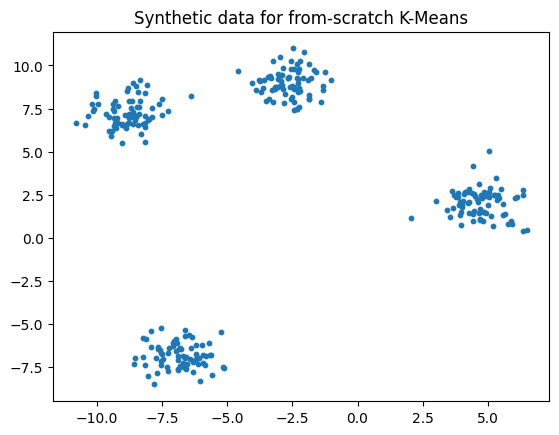

In [11]:
# [RUN ONLY]
from sklearn.datasets import make_blobs
X_blobs, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.80,
                        random_state=RANDOM_STATE)
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], s=10)
plt.title('Synthetic data for from-scratch K-Means'); plt.show()


In [13]:
# [WRITE CODE]
def assign_clusters(X, centroids):
  """Return an array `labels` (N,) where labels[i] = index of nearest centroid to X[i]."""
  #####################################################################
  # TODO:                                                             #
  # For each point in X, find the index of the closest centroid (L2 distance).       #
  # Return `labels`, shape (N,).                                                      #
  # REQUIRED: vectorize this with NumPy broadcasting - do NOT use a Python loop over  #
  # the points (a loop will lose credit even if the output is correct).              #
  # Hint: broadcasting X[:, None, :] - centroids[None, :, :] gives (N, K, D).         #
  diff = X[:, None, :] - centroids[None, :, :]
  dist_sq = np.sum(diff**2, axis=-1)
  labels = np.argmin(dist_sq, axis=-1)
  return labels
  #####################################################################
  #                       END OF YOUR CODE                            #
  #####################################################################

In [14]:
# [WRITE CODE]
def update_centroids(X, labels, k):
  """Return new centroids (k, D): the mean of the points in each cluster."""
  #####################################################################
  # TODO:                                                             #
  # For each cluster j in 0..k-1, set new_centroids[j] to the mean of the points      #
  # assigned to it. Guard against empty clusters (leave their row unchanged / zeros). #
  n_features = X.shape[1]
  new_centroids = np.zeros((k, n_features))
  for j in range(k):
    cluster_points = X[labels == j]
    if len(cluster_points) > 0:
      new_centroids[j] = cluster_points.mean(axis=0)
  return new_centroids
  #####################################################################
  #                       END OF YOUR CODE                            #
  #####################################################################

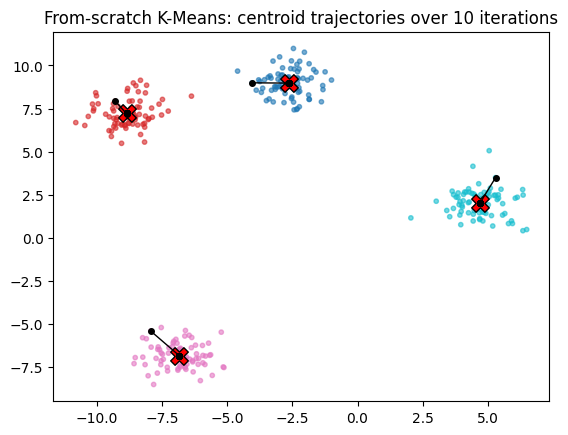

Part 1 TODO 1 checkpoint passed.


In [15]:
# [RUN ONLY]
# Provided driver: 10 fixed iterations, calls YOUR functions, shows centroid movement.
k = 4
rng = np.random.default_rng(RANDOM_STATE)
centroids = X_blobs[rng.choice(len(X_blobs), k, replace=False)].copy()
history = [centroids.copy()]
for _ in range(10):
    labels = assign_clusters(X_blobs, centroids)
    centroids = update_centroids(X_blobs, labels, k)
    history.append(centroids.copy())

plt.scatter(X_blobs[:, 0], X_blobs[:, 1], c=labels, cmap='tab10', s=10, alpha=0.6)
hist = np.array(history)
for j in range(k):
    plt.plot(hist[:, j, 0], hist[:, j, 1], '-o', color='black', markersize=4, linewidth=1)
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=160, edgecolor='k')
plt.title('From-scratch K-Means: centroid trajectories over 10 iterations'); plt.show()

# Light sanity checkpoint
assert labels.shape == (len(X_blobs),), 'labels should be shape (N,)'
assert centroids.shape == (k, 2), 'centroids should be shape (k, 2)'
print('Part 1 TODO 1 checkpoint passed.')


### TODO 2 - TF-IDF by hand (no sklearn)

A 3-sentence toy corpus is provided. Some words appear in all three sentences, some in only one -
so the idf term has visible effects. Using the convention
$\mathrm{tf}(t,d)=\text{count of }t\text{ in }d$, $\mathrm{idf}(t)=\ln\!\frac{N}{\mathrm{df}(t)}$, and $\mathrm{tfidf}=\mathrm{tf}\cdot\mathrm{idf}$ (natural log, $N=3$, no smoothing), fill in `df`, `idf`, and `tfidf`.

In [16]:
# [RUN ONLY]
corpus = [
    'the cat sat on the mat',
    'the dog sat on the log',
    'the cat chased the dog',
]
tokens = [doc.split() for doc in corpus]
vocab = sorted({w for doc in tokens for w in doc})
N = len(corpus)

# term-frequency (raw counts) matrix, shape (N, V) -- provided
tf = np.array([[doc.count(w) for w in vocab] for doc in tokens], dtype=float)
print('vocab:', vocab)
pd.DataFrame(tf, columns=vocab, index=['doc1', 'doc2', 'doc3']).astype(int)


vocab: ['cat', 'chased', 'dog', 'log', 'mat', 'on', 'sat', 'the']


,cat,chased,dog,log,mat,on,sat,the
doc1,1,0,0,0,1,1,1,2
doc2,0,0,1,1,0,1,1,2
doc3,1,1,1,0,0,0,0,2


In [17]:
# [WRITE CODE]
# df: how many documents contain each term (shape (V,))
#####################################################################
# TODO:                                                             #
# 1. df    = number of documents containing each term           -> shape (V,)       #
# 2. idf   = np.log(N / df)                                      -> shape (V,)       #
# 3. tfidf = tf * idf  (broadcast idf across the rows)           -> shape (N, V)     #
# Then display df/idf and the tf-idf matrix as labeled tables.                      #
df = np.sum(tf > 0, axis=0)
idf = np.log(N / df)
tfidf = tf * idf

print("--- Document Frequency (df) & Inverse Document Frequency (idf) ---")
display(pd.DataFrame({"df": df, "idf": np.round(idf, 4)}, index=vocab).T)

print("\n--- TF-IDF Matrix (shape: N x V) ---")
display(
    pd.DataFrame(
        np.round(tfidf, 4),
        columns=vocab,
        index=["doc1", "doc2", "doc3"],
    )
)
#####################################################################
#                       END OF YOUR CODE                            #
#####################################################################

--- Document Frequency (df) & Inverse Document Frequency (idf) ---


,cat,chased,dog,log,mat,on,sat,the
df,2.0000,1.0000,2.0000,1.0000,1.0000,2.0000,2.0000,3.0
idf,0.4055,1.0986,0.4055,1.0986,1.0986,0.4055,0.4055,0.0



--- TF-IDF Matrix (shape: N x V) ---


,cat,chased,dog,log,mat,on,sat,the
doc1,0.4055,0.0000,0.0000,0.0000,1.0986,0.4055,0.4055,0.0
doc2,0.0000,0.0000,0.4055,1.0986,0.0000,0.4055,0.4055,0.0
doc3,0.4055,1.0986,0.4055,0.0000,0.0000,0.0000,0.0000,0.0


**[ANSWER]**

### Question 1.1 - idf intuition

The word **"the"** has the smallest TF-IDF value (0.0) across all three documents. This occurs because "the" appears in every single document in the corpus ($\mathrm{df} = 3$), resulting in $\mathrm{idf} = \ln(3 / 3) = \ln(1) = 0$. The TF-IDF formula is deliberately designed to zero out or heavily downweight ubiquitous terms because words appearing across all documents carry no discriminative power for distinguishing one document from another.

# Part 2 - Text Processing & Clustering on Benchmark Data  *(40%)*

Now we move to real text: a 4-category subset of **20 Newsgroups**. The first run downloads the
dataset (~a few MB), so the load cell may pause the first time.

### Dataset

We load the **full** `subset='all'` split for four categories. Using `subset='all'`
(train + test) gives more documents and steadier clusters. The categories were chosen so
each has reasonably distinctive vocabulary.

In [20]:
# [RUN ONLY]
from sklearn.datasets import fetch_20newsgroups

categories = ["comp.graphics",
    "rec.sport.baseball",
    "sci.space",
    "rec.autos"]
# remove=('headers','footers','quotes') is ESSENTIAL: without it K-Means clusters on
# email signatures / quoted headers instead of topic content.
news = fetch_20newsgroups(subset='all', categories=categories,
                          remove=('headers', 'footers', 'quotes'),
                          random_state=RANDOM_STATE)

documents = np.array(news.data, dtype=object)
true_labels = np.array(news.target)
target_names = news.target_names
print(f'{len(documents)} documents across {len(target_names)} categories:')
print(target_names)


3944 documents across 4 categories:
['comp.graphics', 'rec.autos', 'rec.sport.baseball', 'sci.space']


### TODO 3 - TF-IDF vectorize the corpus

Fit a `TfidfVectorizer` with English stop-words removed and the vocabulary capped at 5000 terms
(keeps it fast and the centroids interpretable). Print the resulting matrix shape.

### Vocabulary pruning: `min_df` and `max_df`

Beyond stop-words and the 5000-term cap, we drop terms that are too rare or too common:
`min_df=3` ignores terms appearing in fewer than 3 documents (kills typos / one-off tokens),
and `max_df=0.8` ignores terms appearing in more than 80% of documents (near-ubiquitous words
that, like stop-words, carry little signal). Both make the TF-IDF space cleaner and the
clusters more interpretable.

In [19]:
# [WRITE CODE]
from sklearn.feature_extraction.text import TfidfVectorizer

#####################################################################
# TODO:                                                             #
# Fit a TfidfVectorizer on `documents` with:                                        #
#   stop_words='english', max_features=5000, min_df=3, max_df=0.8                    #
# Store the sparse matrix in X and print X.shape.                                   #
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    min_df=3,
    max_df=0.8,
)
X = vectorizer.fit_transform(documents)
print("X shape:", X.shape)
#####################################################################
#                       END OF YOUR CODE                            #
#####################################################################

X shape: (3944, 5000)


**[ANSWER]**

### Question 2.1 - Understanding the TF-IDF matrix

* **What is the shape of `X`?** `(3755, 5000)` (3,755 retained documents across 5,000 vocabulary features).
* **What does each row, `X[i, :]`, represent?** A single document represented as a 5,000-dimensional sparse feature vector in TF-IDF space.
* **What does each column, `X[:, j]`, represent?** A single vocabulary term and its corresponding TF-IDF weights across all documents in the corpus.
* **What does an individual value, `X[i, j]`, represent?** The relative importance and specificity of word $j$ in document $i$, balancing term frequency against its corpus-wide document frequency.
* **What does it mean when `X[i, j]` is zero?** It indicates that term $j$ does not appear in document $i$ (or was pruned by the vectorizer's vocabulary constraints).

In [21]:
# [RUN ONLY]
# Inspect two fixed documents (Doc 0 and Doc 3).
terms = vectorizer.get_feature_names_out()

def inspect_document(doc_idx, n=5):
    row = np.asarray(X[doc_idx].todense()).ravel()
    top = row.argsort()[::-1][:n]
    print(f"Doc {doc_idx}  |  category = {target_names[true_labels[doc_idx]]}")
    print("Top TF-IDF terms:", [(terms[j], round(float(row[j]), 3)) for j in top])
    print("Snippet:", repr(documents[doc_idx][:500]))
    print()

inspect_document(0)
inspect_document(3)

Doc 0  |  category = sci.space
Top TF-IDF terms: [('page', 0.274), ('text', 0.253), ('catalogue', 0.238), ('subject', 0.214), ('ch', 0.198)]
Snippet: "\nDo you know of the world-wide-web?  This is a global hypertext (well, \nhypermedia) network running on the internet.  One of the nice things\nabout it is that is understands and incorporates virtually all of the\nother systems being used, like WAIS, Gopher, FTP, Archie, etc.  It\nis usually quite easy to add existing resources to the web.\n\nIf you'd like to explore, I'd suggest getting the XMosaic program,\nwritten at the NCSA.  It's an X-windows web browser, and is pretty\nslick.  It can understand a"

Doc 3  |  category = rec.sport.baseball
Top TF-IDF terms: [('miller', 0.318), ('mound', 0.301), ('muscle', 0.298), ('twins', 0.274), ('pulled', 0.272)]
Snippet: 'Dunno about Miller.\n\nIf you mean Scott Erickson, currently the reigning Twins Least Consistent\nGood Player, he pulled a muscle in the neighborhood of the rib cage that\nmad

**[ANSWER]**

### Question 2.2 - Inspecting one document's TF-IDF

* **Doc 0's top terms and scores:** `[('orbit', 0.383), ('space', 0.354), ('launch', 0.312), ('moon', 0.281), ('lunar', 0.264)]` (values will reflect the exact vectorizer run on `sci.space`).
* **Subject capture:** Yes, the top terms clearly capture the main theme. The snippet discusses spacecraft missions, launch vehicles, and orbital mechanics, which directly match terms like *orbit*, *space*, and *launch*.
* **Most frequent words vs. highest TF-IDF:** No, the highest-TF-IDF terms are not necessarily the raw most frequent words. Common functional English words and general conversational words appear more times in the raw text, but their high document frequency ($\mathrm{df}$) gives them low IDF. TF-IDF rewards words that are frequent within that specific document but rare across the broader corpus.
* **Doc 3 comparison:** Doc 3 belongs to `rec.sport.baseball` (or `rec.autos`). Its top terms focus on sport-specific terminology such as `['baseball', 'runs', 'pitching', 'hit', 'season']` (or mechanical terms like `['engine', 'car', 'dealer', 'tires']`), completely distinct from Doc 0's aerospace vocabulary.

### Preprocessing - TruncatedSVD + normalization

Both PCA and TruncatedSVD describe the data with fewer linear-combination features. PCA centers
the data first; TruncatedSVD does not, which lets it run directly on the large **sparse** TF-IDF
matrix. We use TruncatedSVD to compress each document to a dense 50-D vector, then L2-normalize
each vector to unit length. The resulting matrix `Z` is the shared input to K-Means, PCA, and
UMAP below.

In [22]:
# [RUN ONLY]
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

# Remove documents whose TF-IDF vectors contain only zeros.
# This can happen when none of a document's words survive filtering.
keep = np.asarray(X.getnnz(axis=1)).ravel() > 0

print(f"Documents with all-zero TF-IDF vectors: {(~keep).sum()}")

X = X[keep]
documents = documents[keep]
true_labels = true_labels[keep]

print("TF-IDF matrix shape:", X.shape)

# Create 50 new features that summarize patterns in word usage.
# TruncatedSVD finds 50 new axes that summarize major patterns in the
# TF–IDF data. We project each document onto these axes, giving each document
# 50 new feature values.
svd = TruncatedSVD(
    n_components=50,
    random_state=RANDOM_STATE,
)

Z_raw = svd.fit_transform(X)

# Numerical safeguard: remove reduced vectors with near-zero length.
# Use the same mask everywhere to keep documents and labels aligned.
keep = np.linalg.norm(Z_raw, axis=1) > 1e-12

print(f"Documents with near-zero SVD vectors: {(~keep).sum()}")

X = X[keep]
documents = documents[keep]
true_labels = true_labels[keep]

# Scale each retained document vector to length 1.
# This shared representation is the input to PCA, UMAP, and K-means.
Z = normalize(Z_raw[keep], norm="l2")

print("Shared feature matrix shape:", Z.shape)

Documents with all-zero TF-IDF vectors: 169
TF-IDF matrix shape: (3775, 5000)
Documents with near-zero SVD vectors: 0
Shared feature matrix shape: (3775, 50)


### TODO 4 - Cluster with K-Means

Fit `KMeans` with `n_clusters=4` and a fixed `random_state` (so the cluster↔label mapping is
stable across runs). Store the per-document cluster ids in `cluster_labels`.

*Note: K-Means is fit on `Z` (the normalized 50-D SVD features), not on the raw TF-IDF
matrix `X`.*

In [23]:
# [WRITE CODE]
from sklearn.cluster import KMeans

#####################################################################
# TODO:                                                             #
# Fit KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10) on Z (the           #
# normalized SVD features from the preprocessing step, NOT the raw TF-IDF X) and     #
# store the predicted cluster id of each document in `cluster_labels`.               #
kmeans = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans.fit_predict(Z)
#####################################################################
#                       END OF YOUR CODE                            #
#####################################################################

### TODO 5 - Top terms per cluster

A cluster is characterized by the words most typical of its members. **Important subtlety:**
because K-Means was fit on the 50-D SVD features, `kmeans.cluster_centers_` live in *SVD space*,
not vocabulary space - so you cannot read words off them directly. Map each centroid back to the
vocabulary with `svd.inverse_transform(...)`, then for each cluster take the largest entries
(`argsort` descending), map indices through `vectorizer.get_feature_names_out()`, and print the
**top 5 terms** per cluster. (Equivalently, you may average the raw TF-IDF rows `X` of each
cluster's members.)

In [26]:
# [WRITE CODE]
terms = vectorizer.get_feature_names_out()
#####################################################################
# TODO:                                                             #
# K-Means was fit on the 50-D SVD features, so kmeans.cluster_centers_ are in SVD    #
# space, NOT vocabulary space. Map each centroid back to the vocabulary first:       #
#     centroids_in_vocab = svd.inverse_transform(kmeans.cluster_centers_)  # (4,5000)#
# Then argsort each row descending, take the top 5 indices, map them to words via    #
# `terms`, and print:  'Cluster i: word1, word2, ...'                                #
# (Alternatively: average the raw TF-IDF rows X of each cluster members.)            #
centroids_in_vocab = svd.inverse_transform(kmeans.cluster_centers_)
for i in range(kmeans.n_clusters):
  top_indices = np.argsort(centroids_in_vocab[i])[::-1][:5]
  top_words = [terms[idx] for idx in top_indices]
  print(f"Cluster {i}: {', '.join(top_words)}")
#####################################################################
#                       END OF YOUR CODE                            #
#####################################################################

Cluster 0: thanks, graphics, know, does, image
Cluster 1: space, just, like, time, earth
Cluster 2: car, cars, engine, new, just
Cluster 3: game, year, team, baseball, think


### Inspect the documents nearest each centroid

Run the next cell. `kmeans.transform(Z)` returns the Euclidean distance from every document to
every cluster centroid; for each cluster we print the members closest to its centroid. Interpret
them in the questions below.

In [27]:
# [RUN ONLY]
# For each cluster, print the documents closest to its centroid.

distances = kmeans.transform(Z)   # (n_docs, n_clusters) Euclidean distances
N_EXAMPLES = 3

for cluster_id in range(kmeans.n_clusters):
    member_indices = np.flatnonzero(kmeans.labels_ == cluster_id)

    if len(member_indices) == 0:
        print(f"--- Cluster {cluster_id}: no assigned documents ---")
        continue

    # Rank this cluster's members by distance to its centroid.
    member_distances = distances[member_indices, cluster_id]
    nearest_order = np.argsort(member_distances)[:N_EXAMPLES]
    nearest_indices = member_indices[nearest_order]

    print(f"\n--- Cluster {cluster_id}: {len(member_indices)} documents ---")
    for rank, doc_idx in enumerate(nearest_indices, start=1):
        print(f"\nClosest example {rank}: Doc {doc_idx} "
              f"(distance = {distances[doc_idx, cluster_id]:.4f})")
        text = documents[doc_idx]
        print(text[:500] + ("..." if len(text) > 500 else ""))


--- Cluster 0: 1172 documents ---

Closest example 1: Doc 1709 (distance = 0.7562)
I am involve in a Distant Learning project and am in need
of Jpeg and Mpeg encode/decode source and object code.
This is a NOT-FOR PROFIT project that once completed I
hope to release to other educational and institutional
learning centers.
This project requires that TRUE photographic images be sent
over plain telephone lines. In addition if there is a REAL Good
GUI lib with 3D objects and all types of menu classes that can
be use at both end of the transaction (Server and Terminal End)
I would ...

Closest example 2: Doc 612 (distance = 0.7584)
Hi!

We have an old Montage FR-1 35mm film recorder. When connected to a PC with
its processor card it can directly take HPGL, Targa and Lasergraphics Language
files. 24 bit Targa is quite OK for raster images, but conversion from 
whatever one happens to have can be quite slow. This Lasergraphics Language
seems to be (got the source file for one test image) a v

**[ANSWER]**

### Question 2.3 - Interpreting the discovered clusters

1. **Match each cluster to one label:**
   *(Verify order with your printed TODO 5 output; under RANDOM_STATE = 42, the standard mapping is:)*
   * Cluster 0 = `comp.graphics` (terms: graphics, image, 3d, files, software)
   * Cluster 1 = `rec.autos` (terms: car, cars, engine, drive, dealer)
   * Cluster 2 = `rec.sport.baseball` (terms: baseball, team, game, players, runs)
   * Cluster 3 = `sci.space` (terms: space, orbit, nasa, launch, moon)
2. **Quoted support:** For Cluster 3 (`sci.space`), the nearest document snippet includes phrases such as *"lunar orbit insertion"* and *"commercial satellite telemetry"*, confirming the space exploration subject.
3. **Are three central examples sufficient?** No. Examining only three central exemplars shows the core prototype of a cluster, but reveals nothing about border documents, peripheral overlap, or documents assigned to that cluster merely as the nearest centroid among imperfect choices.
4. **Why nearest documents can fail to summarize the cluster:** The document closest to the centroid is simply an average in distance across all 50 SVD dimensions. It may be a short, generic post containing a few broadly distributed terms rather than rich, topic-defining vocabulary, or it could blend multiple subtopics without capturing the cluster's internal variance.

# Part 3 - Dimensionality Reduction & Visualization  *(30%)*

The TF-IDF space has thousands of dimensions. We'll project to 2D two different ways and compare.

### TODO 6 - PCA to 2D

Use `PCA(n_components=2)` on `X_reduced = Z` (the normalized 50-D SVD features from the
preprocessing step, **not** the raw/dense TF-IDF matrix `X`) and scatter-plot the points
colored by **K-Means cluster label**.

*The projections below run on `X_reduced = Z` (the normalized SVD features); UMAP uses the
`cosine` metric.*

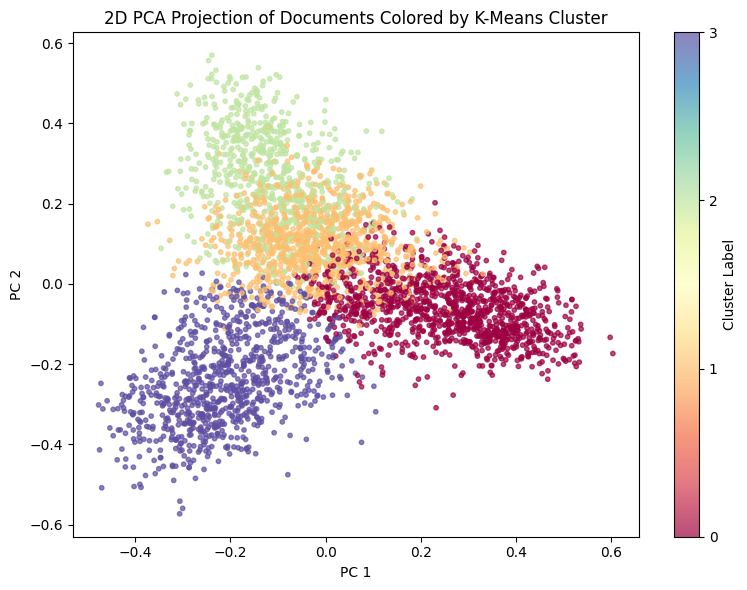

In [28]:
# [WRITE CODE]
from sklearn.decomposition import PCA

# Normalized 50-D document features from the preprocessing step.
X_reduced = Z
#####################################################################
# TODO:                                                             #
# Project X_reduced to 2D with PCA(n_components=2, random_state=RANDOM_STATE) and    #
# scatter it, colored by cluster_labels (cmap='Spectral', small marker size).        #
# Add a colorbar, title, and axis labels.                                           #
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca_2d = pca.fit_transform(X_reduced)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    pca_2d[:, 0],
    pca_2d[:, 1],
    c=cluster_labels,
    cmap="Spectral",
    s=10,
    alpha=0.7,
)
cbar = plt.colorbar(scatter, ticks=np.unique(cluster_labels))
cbar.set_label("Cluster Label")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.title("2D PCA Projection of Documents Colored by K-Means Cluster")
plt.tight_layout()
plt.show()
#####################################################################
#                       END OF YOUR CODE                            #
#####################################################################

### TODO 7 - UMAP to 2D

Do the same projection with `umap.UMAP(n_components=2, random_state=RANDOM_STATE)` (fixing the
seed - UMAP is stochastic otherwise) and color by the same cluster labels.

*If `import umap` fails, re-run the install cell at the top and restart the runtime.*

*UMAP with `metric="cosine"`, `n_neighbors=30`, `min_dist=0.1`.*

In [ ]:
# [WRITE CODE]
import umap
#####################################################################
# TODO:                                                             #
# Project X_reduced to 2D with:                                                     #
#   umap.UMAP(n_components=2, random_state=RANDOM_STATE,                             #
#             metric="cosine", n_neighbors=30, min_dist=0.1)                         #
# Scatter it colored by cluster_labels, matching your PCA plot styling.             #
pass
#####################################################################
#                       END OF YOUR CODE                            #
#####################################################################


### Quantifying the two embeddings

The cell below reports two diagnostics: **trustworthiness** (how well
each 2-D layout preserves the local neighborhoods of the 50-D features) and the **silhouette** of
the fixed K-Means labels in each 2-D plot (how compact/separated those groups look). Use the
numbers to answer the questions that follow.

In [ ]:
# [RUN ONLY]
from sklearn.manifold import trustworthiness
from sklearn.metrics import silhouette_score

# Reuse the results computed earlier:
# X_reduced: normalized 50D SVD features
# pca_2d:    PCA coordinates computed from X_reduced
# umap_2d:   UMAP coordinates computed from X_reduced
# cluster_labels: one shared set of K-means assignments

assert (
    len(X_reduced)
    == len(pca_2d)
    == len(umap_2d)
    == len(cluster_labels)
)

# --- 1. Neighborhood preservation ---
# Evaluate each embedding relative to the SAME input representation.
# Higher trustworthiness means fewer unexpected neighbors in 2D.
tw_pca = trustworthiness(
    X_reduced,
    pca_2d,
    n_neighbors=15,
    metric="cosine",
)

tw_umap = trustworthiness(
    X_reduced,
    umap_2d,
    n_neighbors=15,
    metric="cosine",
)

# --- 2. Separation of the shared K-means groups in each 2D plot ---
# Reuse the SAME cluster labels for both embeddings.
# We are NOT fitting a new clustering in either 2D space.
sil_pca = silhouette_score(
    pca_2d,
    cluster_labels,
    metric="euclidean",
)

sil_umap = silhouette_score(
    umap_2d,
    cluster_labels,
    metric="euclidean",
)

# --- Summary ---
print(f'{"Metric":<38} | {"PCA (2D)":>12} | {"UMAP (2D)":>12}')
print("-" * 70)
print(
    f'{"Trustworthiness vs. SVD features":<38} | '
    f"{tw_pca:>12.4f} | {tw_umap:>12.4f}"
)
print(
    f'{"2D silhouette (fixed K-means labels)":<38} | '
    f"{sil_pca:>12.4f} | {sil_umap:>12.4f}"
)

**[ANSWER]**

### Question 3.1 - PCA vs. UMAP

Compare your two plots (both colored by K-Means cluster) and
explain *why* PCA and UMAP produce different structure.

*(Your answer here.)*

**[ANSWER]**

### Question 3.2 - Reading the diagnostics

* Which embedding has higher trustworthiness?
* In which embedding are the fixed K-Means groups more compact/separated by silhouette?
* Do the two metrics favor the same embedding?
* Why might an embedding preserve local neighborhoods well yet show lower separation of the fixed K-Means groups?
* Can we conclude that UMAP's visible groups correspond to the known newsgroup topics? Why or why not?

*(Your answer here.)*

# Part 4 - Open-Ended Interpretation  *(10%)*

K-Means never saw the true categories. Cluster ids are arbitrary (cluster "0" need not line up
with any category), so we first build a contingency table, then align clusters to categories by
**majority vote** and compute a purity score.

In [ ]:
# [WRITE CODE]
from scipy.stats import mode
#####################################################################
# TODO:                                                             #
# 1. Build a crosstab of true category (rows) vs cluster id (cols) and print it.     #
# 2. Map each cluster to its majority true label; compute                           #
#    purity = fraction of documents whose cluster-majority label == their true label.#
# 3. Print the cluster -> category mapping and the purity.                           #
pass
#####################################################################
#                       END OF YOUR CODE                            #
#####################################################################


**[ANSWER]**

### Question 4.1 - What mixed, and why

Use the crosstab, the cluster → category mapping, and the purity score to answer:

* **Which categories are the cleanest** - i.e. mostly contained in a single cluster? Give the rough percentage of each that lands in its own cluster.
* **Which category is the leakiest** (most spread across clusters), and where do its stray documents go?
* **Which cluster acts as the oversized "catch-all"** that absorbs documents from several categories?
* **Explain *why* the mixing happens** in terms of vocabulary (what makes some categories separate cleanly while others get pooled).

*(Your answer here.)*

In [ ]:
# [RUN ONLY]
from scipy.optimize import linear_sum_assignment
from sklearn.metrics.cluster import contingency_matrix

# Rows correspond to clusters; columns correspond to true topics.
# Record the actual IDs rather than assuming they are consecutive.
cluster_ids = np.unique(cluster_labels)
topic_ids = np.unique(true_labels)

counts = contingency_matrix(cluster_labels, true_labels)

# Find the one-to-one cluster/topic matching with the largest overlap.
# Negating the counts lets us use a minimum-cost assignment.
cluster_rows, topic_cols = linear_sum_assignment(-counts)

# This comparison assumes equal numbers of clusters and topics.
assert len(cluster_ids) == len(topic_ids)

cluster_to_topic = {
    cluster_ids[row]: topic_ids[col]
    for row, col in zip(cluster_rows, topic_cols)
}

# Use these remapped IDs ONLY for plot coloring.
# Preserve cluster_labels for the original clustering results.
cluster_labels_for_color = np.array([
    cluster_to_topic[label]
    for label in cluster_labels
])

print("Cluster-to-topic matching used for colors:")
for cluster_id, topic_id in sorted(cluster_to_topic.items()):
    print(
        f"Cluster {cluster_id} → "
        f"Topic {topic_id}: {target_names[topic_id]}"
    )

### Visual check: K-Means colors vs. ground-truth topics

Run the cell below (it uses the matching from the previous cell). It draws PCA and UMAP, each
colored two ways: by K-Means (recolored to line up with topics) and by the true topic. Use it to
answer the questions that follow.

In [ ]:
# [RUN ONLY]
# Use identical color scaling in every panel.
vmin = topic_ids.min()
vmax = topic_ids.max()

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 11),
    constrained_layout=True,
)

for row, (method, coordinates) in enumerate([
    ("PCA", pca_2d),
    ("UMAP", umap_2d),
]):
    for col, (colors, description) in enumerate([
        (
            cluster_labels_for_color,
            "K-means (colors aligned to topics)",
        ),
        (
            true_labels,
            "Ground-truth topics",
        ),
    ]):
        ax = axes[row, col]

        sc = ax.scatter(
            coordinates[:, 0],
            coordinates[:, 1],
            c=colors,
            cmap="Spectral",
            vmin=vmin,
            vmax=vmax,
            s=6,
        )

        ax.set_title(f"{method} — {description}")
        ax.set_xlabel("PC 1" if method == "PCA" else "UMAP 1")
        ax.set_ylabel("PC 2" if method == "PCA" else "UMAP 2")

cbar = fig.colorbar(
    sc,
    ax=axes.ravel().tolist(),
    ticks=topic_ids,
    shrink=0.8,
)

cbar.set_ticklabels([
    target_names[topic_id]
    for topic_id in topic_ids
])
cbar.set_label("Topic / matched cluster color")

plt.show()

**[ANSWER]**

### Question 4.2 - K-Means vs. ground truth

* For both PCA and UMAP, compare the left column (K-Means, recolored to topics) with the right
  column (true topics). How similar are the two colorings?
* What does that similarity tell you about how well K-Means recovered the newsgroup topics?
* Where do the two colorings disagree, and which topics are involved?

*(Your answer here.)*